# Praktikum TinyML — Klasifikasi Getaran Kompresor (X dan Z, 6 Fitur)

**Teknik Otomasi — Jurusan Teknik Elektro, Politeknik Negeri Bali**  
**Perangkat:** ESP32 + MPU6050  
**Tujuan:** membandingkan fitur sensor, melatih model, dan menjalankan inferensi pada mikrokontroler.

**Alur praktikum:** Upload ZIP → validasi sinyal → windowing → ekstraksi 6 fitur → perbandingan model validation → evaluasi test → visualisasi Decision Tree → ekspor model → prediksi langsung di ESP32.

> Label `anomali` menunjukkan perubahan kondisi percobaan, **bukan diagnosis kerusakan kompresor**. Model kecil tidak dijamin memberikan akurasi lebih tinggi. Tujuan praktikum adalah memahami kompromi akurasi, kompleksitas model, dan sumber daya ESP32.


## Tahap 1 — Persiapan dan parameter

Parameter ini **harus sama** dengan program pengumpulan data lama. Konversi `8192` berlaku untuk accelerometer MPU6050 **±4g**. Bila rekaman baru menggunakan ±8g, **jangan digabung dengan data lama tanpa mencatat dan menyesuaikan pengaturan**.

In [1]:
# Library yang tersedia di Google Colab
import io, re, math, zipfile, hashlib, importlib.util, shutil, gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from google.colab import files

# Parameter percobaan lama
FS = 200                  # target: 200 sampel per detik
WINDOW = 200              # 1 window = sekitar 1 detik
SKALA = 8192.0            # MPU6050 +/-4g = 8192 LSB/g
SEED = 42
JUMLAH_FILE_PER_KELAS = 15
KELAS = ["normal", "anomali"]
SUMBU = ["ax_raw", "az_raw"]  # Y SENGAJA tidak dipakai!
FITUR_4 = ["rms_x", "rms_z", "ptp_x", "ptp_z"]
FITUR = FITUR_4 + ["diff_x", "diff_z"]  # Urutan ini HARUS konsisten hingga ESP32

print("Target:", FS, "Hz, window:", WINDOW, "sampel")
print("Baseline 4 fitur:", FITUR_4)
print("TinyML 6 fitur:", FITUR)

Target: 200 Hz, window: 200 sampel
Baseline 4 fitur: ['rms_x', 'rms_z', 'ptp_x', 'ptp_z']
TinyML 6 fitur: ['rms_x', 'rms_z', 'ptp_x', 'ptp_z', 'diff_x', 'diff_z']


## Tahap 2 — Upload file ZIP dari laptop

Unggah **satu dataset kelompok** setiap kali menjalankan notebook. ZIP boleh berisi subfolder `normal/` dan `anomali/`, atau CSV bernama `normal_01.csv`, `anomali_01.csv`, dst. **Jangan mencampur data beberapa kelompok** karena kondisi pengukuran dapat berbeda dan mungkin ada rekaman yang sama.

In [2]:
# Google Colab akan menampilkan tombol untuk memilih ZIP dari laptop.
unggahan = files.upload()
nama_zip = next((n for n in unggahan if n.lower().endswith(".zip")), None)
if nama_zip is None:
    raise ValueError("Silakan unggah satu file ZIP dataset kompresor terlebih dahulu.")
print("Dataset terpilih:", nama_zip)

Saving dataset_kompresor.zip to dataset_kompresor.zip
Dataset terpilih: dataset_kompresor.zip


## Tahap 3 — Membaca CSV dan memeriksa kualitas data

**Tujuan:** memastikan file dapat digunakan, mengecek timestamp serta mengukur persentase pembacaan yang menyentuh batas digital sensor.

- `clipping_y` hanya dipantau sebagai **diagnostik**. Data Y tidak masuk model.
- File kosong dan CSV tanpa label yang jelas dilewati.
- Jika ZIP berisi lebih dari 15 rekaman valid per kelas, dipakai **15 file pertama menurut nomor nama file**. Daftar pilihannya ditampilkan untuk diperiksa.
- Jika ada kurang dari 15 file valid per kelas, program berhenti agar pembagian 9/3/3 tetap konsisten.


Jumlah file yang digunakan:
label
normal     15
anomali    15
Name: count, dtype: int64

Daftar file:


,file,label,sampel,fs_aktual,clip_x_pct,clip_y_pct,clip_z_pct
0,dataset_kompresor/anomali/anomali_01.csv,anomali,6000,200.000313,0.0,59.183333,0.0
1,dataset_kompresor/anomali/anomali_02.csv,anomali,6000,200.000253,0.0,58.900000,0.0
2,dataset_kompresor/anomali/anomali_03.csv,anomali,6000,200.000313,0.0,69.366667,0.0
3,dataset_kompresor/anomali/anomali_04.csv,anomali,6000,200.000260,0.0,84.616667,0.0
4,dataset_kompresor/anomali/anomali_05.csv,anomali,6000,200.000253,0.0,87.050000,0.0
5,dataset_kompresor/anomali/anomali_06.csv,anomali,6000,200.000307,0.0,69.583333,0.0
6,dataset_kompresor/anomali/anomali_07.csv,anomali,6000,200.000260,0.0,51.950000,0.0
7,dataset_kompresor/anomali/anomali_08.csv,anomali,6000,200.000227,0.0,70.050000,0.0
8,dataset_kompresor/anomali/anomali_09.csv,anomali,6000,200.000260,0.0,68.950000,0.0
9,dataset_kompresor/anomali/anomali_10.csv,anomali,6000,200.000260,0.0,65.733333,0.0


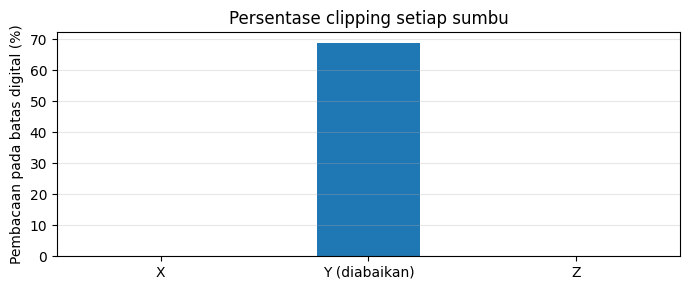

In [3]:
# Fungsi pembaca label dan pengurutan nama berdasarkan angka (01, 02, ..., 10).
def cari_label(nama):
    p = Path(nama)
    for teks in [p.stem.lower()] + [x.lower() for x in p.parts[:-1]]:
        if teks.startswith(("anomali", "abnormal", "modified_support")):
            return "anomali"
        if teks.startswith("normal"):
            return "normal"
    return None

def urut_angka(nama):
    return [int(x) if x.isdigit() else x.lower()
            for x in re.split(r"(\d+)", nama)]

rekaman_semua = {}
catatan = []
with zipfile.ZipFile(io.BytesIO(unggahan[nama_zip])) as z:
    daftar_csv = sorted([n for n in z.namelist() if n.lower().endswith(".csv")
                         and "__macosx" not in n.lower()], key=urut_angka)
    for nama in daftar_csv:
        label = cari_label(nama)
        if label is None:
            print("Lewati (bukan rekaman berlabel):", nama)
            continue
        try:
            df = pd.read_csv(z.open(nama))
        except Exception as err:
            print("Lewati (gagal dibaca):", nama, err)
            continue
        df.columns = df.columns.astype(str).str.strip().str.lower()
        if not set(SUMBU).issubset(df.columns):
            print("Lewati (kolom X/Z tidak ada):", nama)
            continue
        # Nilai raw harus angka. Baris tidak valid menyebabkan file dilewati
        # agar urutan waktu dan isi window tidak berubah diam-diam.
        data_sensor = df[SUMBU].apply(pd.to_numeric, errors="coerce")
        if data_sensor.isna().any().any() or not np.isfinite(data_sensor.to_numpy(dtype=float)).all():
            print("Lewati (ada data X/Z kosong/tidak valid):", nama)
            continue
        if len(df) < WINDOW:
            print("Lewati (terlalu sedikit sampel):", nama)
            continue
        if ((data_sensor < -32768) | (data_sensor > 32767)).any().any():
            print("Lewati (nilai raw di luar int16):", nama)
            continue

        # Kolom timestamp dipakai untuk diagnostik, bukan fitur model.
        t = pd.to_numeric(df["t_us"], errors="coerce") if "t_us" in df else None
        if t is not None and (t.isna().any() or not np.isfinite(t).all()):
            print("Lewati (timestamp tidak valid):", nama)
            continue
        dt = np.diff(t.to_numpy()) if t is not None else np.array([])
        if len(dt) and np.any(dt <= 0):
            print("Lewati (timestamp tidak naik):", nama)
            continue
        fs_aktual = (1e6 / dt.mean()) if len(dt) else np.nan

        xz = data_sensor.to_numpy(dtype=np.int32)
        clip_x = 100.0 * np.mean((xz[:,0] <= -32768) | (xz[:,0] >= 32767))
        clip_z = 100.0 * np.mean((xz[:,1] <= -32768) | (xz[:,1] >= 32767))
        if "ay_raw" in df:
            y = pd.to_numeric(df["ay_raw"], errors="coerce").to_numpy()
            clip_y = 100.0 * np.mean((y <= -32768) | (y >= 32767))
        else:
            clip_y = np.nan
        digest = hashlib.sha256(xz.tobytes()).hexdigest()

        rekaman_semua[nama] = {"label": label, "xz": xz, "t": t, "digest": digest}
        catatan.append({"file": nama, "label": label, "sampel": len(df),
                        "fs_aktual": fs_aktual, "clip_x_pct": clip_x,
                        "clip_y_pct": clip_y, "clip_z_pct": clip_z, "hash_xz": digest})

info_semua = pd.DataFrame(catatan)
if info_semua.empty:
    raise ValueError("Tidak ada file CSV valid. Periksa ZIP dan nama file.")

# Memilih tepat 15 file per kelas; jika ada file ekstra, tampilkan informasinya.
file_dipakai = []
for k in KELAS:
    daftar = sorted(info_semua.loc[info_semua.label == k, "file"].tolist(), key=urut_angka)
    if len(daftar) < JUMLAH_FILE_PER_KELAS:
        raise ValueError(f"Kelas {k}: hanya {len(daftar)} file valid; diperlukan 15.")
    if len(daftar) > JUMLAH_FILE_PER_KELAS:
        print(f"CATATAN: {k} memiliki {len(daftar)} file; hanya 15 pertama digunakan.")
        print("File ekstra:", daftar[JUMLAH_FILE_PER_KELAS:])
    file_dipakai += daftar[:JUMLAH_FILE_PER_KELAS]

info = info_semua[info_semua.file.isin(file_dipakai)].copy().reset_index(drop=True)
rekaman = {f: rekaman_semua[f] for f in file_dipakai}
print("\nJumlah file yang digunakan:")
print(info.label.value_counts().reindex(KELAS))
print("\nDaftar file:")
display(info[["file", "label", "sampel", "fs_aktual", "clip_x_pct", "clip_y_pct", "clip_z_pct"]])

# Deteksi file dengan sinyal X/Z identik dalam kelompok sendiri.
duplikat = info[info.duplicated("hash_xz", keep=False)]
if not duplikat.empty:
    print("PERINGATAN: ditemukan rekaman X/Z identik. Periksa file berikut:")
    display(duplikat[["file", "label"]])
    raise ValueError("Perbaiki rekaman duplikat sebelum training untuk menghindari kebocoran data.")

if (info[["clip_x_pct", "clip_z_pct"]] > 0.1).any().any():
    print("PERINGATAN: X/Z juga clipping. Evaluasi kualitas data sebelum deployment.")
if info["fs_aktual"].notna().any() and ((info["fs_aktual"] - FS).abs() > 0.05*FS).any():
    print("PERINGATAN: ada sampling yang berbeda > 5% dari target.")

# Grafik clipping rata-rata: Y hanya sebagai pembanding, bukan input model.
info[["clip_x_pct", "clip_y_pct", "clip_z_pct"]].mean().rename({
    "clip_x_pct":"X", "clip_y_pct":"Y (diabaikan)", "clip_z_pct":"Z"
}).plot(kind="bar", figsize=(7,3), rot=0)
plt.title("Persentase clipping setiap sumbu")
plt.ylabel("Pembacaan pada batas digital (%)")
plt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## Tahap 4 — Visualisasi sinyal X dan Z

Kita menggambar **2 detik pertama** pada dua kondisi. Sumbu Y tidak ditampilkan karena sebelumnya banyak pembacaan menyentuh batas ±4g.

Amati: apakah amplitudo dan bentuk getaran terlihat berbeda? Perubahan sinyal **tidak harus** selalu membuat amplitudo lebih besar.

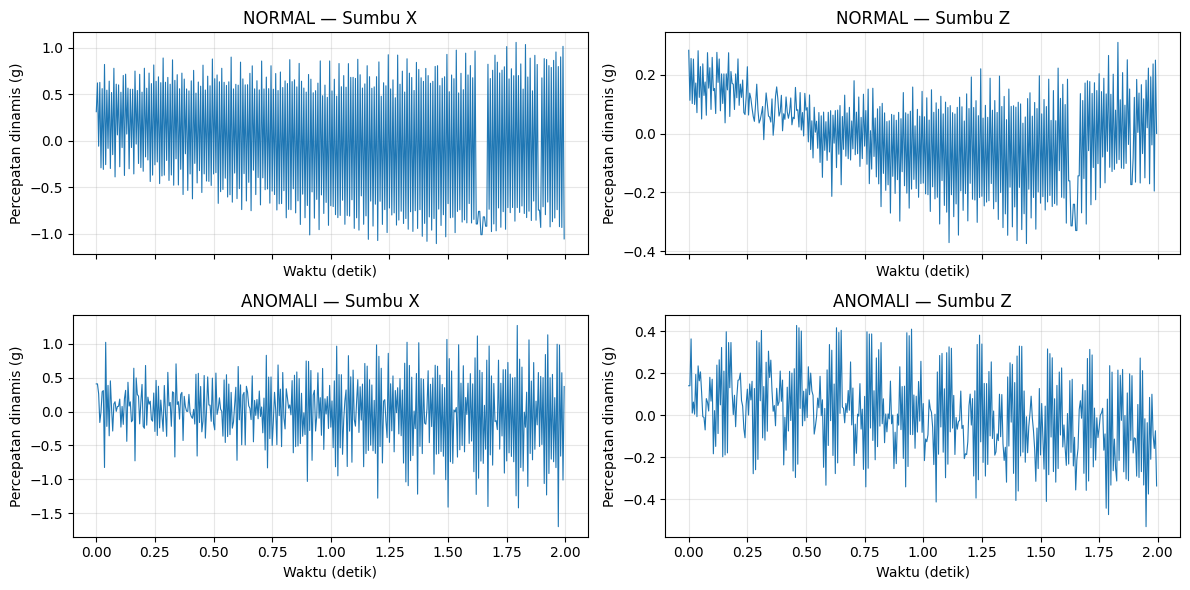

In [4]:
# Ambil contoh satu file normal dan satu file anomali.
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for r, k in enumerate(KELAS):
    f = info.loc[info.label == k, "file"].iloc[0]
    raw = rekaman[f]["xz"][:2*FS] / SKALA
    raw = raw - raw.mean(axis=0)  # hanya untuk melihat getaran dinamis
    t = np.arange(len(raw)) / FS
    for j, arah in enumerate(["X", "Z"]):
        axes[r,j].plot(t, raw[:,j], linewidth=.8)
        axes[r,j].set_title(f"{k.upper()} — Sumbu {arah}")
        axes[r,j].set_xlabel("Waktu (detik)")
        axes[r,j].set_ylabel("Percepatan dinamis (g)")
        axes[r,j].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Tahap 5 — Windowing: satu rekaman menjadi beberapa contoh ML

**Window = 200 sampel**, kira-kira 1 detik. Dari satu file 6.000 sampel kita memperoleh **30 window**. Setiap window nanti akan menjadi **satu baris input model**.

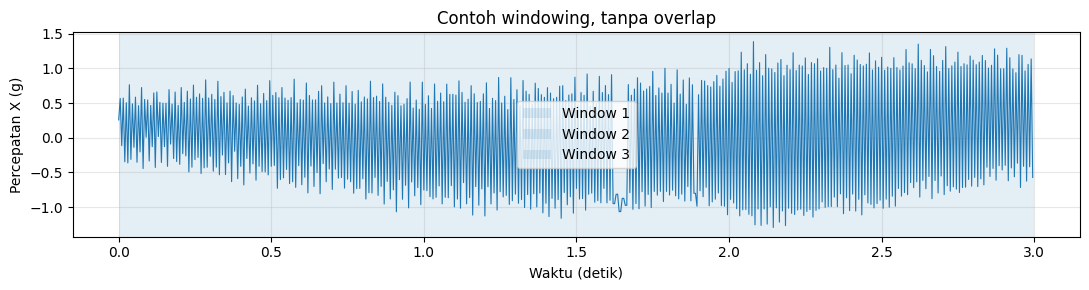

In [5]:
# Ilustrasi tiga window pertama dari satu file normal, sumbu X.
f = info.loc[info.label == "normal", "file"].iloc[0]
x = rekaman[f]["xz"][:3*WINDOW, 0].astype(float) / SKALA
x = x - x.mean()
t = np.arange(len(x)) / FS
plt.figure(figsize=(11,3))
plt.plot(t, x, linewidth=.8)
for i in range(3):
    plt.axvspan(i*WINDOW/FS, (i+1)*WINDOW/FS, alpha=.12, label=f"Window {i+1}")
plt.xlabel("Waktu (detik)")
plt.ylabel("Percepatan X (g)")
plt.title("Contoh windowing, tanpa overlap")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## Tahap 6 — Ekstraksi **6 fitur** ringan (tanpa FFT)

Untuk setiap window 200 sampel, kita menghitung:

| Fitur | Penjelasan |
|---|---|
| `rms_x`, `rms_z` | Besar getaran efektif setelah dikurangi rata-rata |
| `ptp_x`, `ptp_z` | Selisih nilai maksimum dan minimum |
| `diff_x`, `diff_z` | Rata-rata **nilai mutlak selisih dua sampel berturut-turut** |

Contoh `diff_x`: jika X = `[1, 3, 2]`, perbedaannya `[2, 1]` dan hasil rata-ratanya `1,5`.

Rumus: `diff_x = mean(abs(x[1:] - x[:-1]))`. Fitur ini menggambarkan **seberapa cepat amplitudo berubah antarsampel**; bukan otomatis mengukur kerusakan atau frekuensi sebenarnya (sampling terbatas 200 Hz).

Semua fitur dalam `g`, dan urutan input ke model adalah **`[rms_x, rms_z, ptp_x, ptp_z, diff_x, diff_z]`**. Sumbu Y tidak digunakan karena hasil akuisisi lama mengalami clipping.


In [6]:
def ekstrak_fitur(raw_xz):
    """Ubah satu window MPU6050 (200x2 raw int) menjadi enam angka."""
    g = np.asarray(raw_xz, dtype=np.float64) / SKALA
    g = g - np.mean(g, axis=0)  # Hilangkan komponen DC tiap sumbu
    rms = np.sqrt(np.mean(g * g, axis=0))
    ptp = np.max(g, axis=0) - np.min(g, axis=0)
    # Perubahan antarsampel berurutan: sederhana untuk ESP32
    diff = np.mean(np.abs(np.diff(g, axis=0)), axis=0)
    return [rms[0], rms[1], ptp[0], ptp[1], diff[0], diff[1]]

# Contoh: 200 sampel pertama satu rekaman
raw_contoh = rekaman[f]["xz"][:WINDOW]
print("Ukuran satu window:", raw_contoh.shape)
print(pd.Series(ekstrak_fitur(raw_contoh), index=FITUR).round(5))


Ukuran satu window: (200, 2)
rms_x     0.58485
rms_z     0.12178
ptp_x     1.90942
ptp_z     0.58105
diff_x    1.11291
diff_z    0.14714
dtype: float64


## Tahap 7 — Membuat dataset fitur

Setiap file dipecah menjadi window dan diubah menjadi baris dengan 6 fitur. Kolom `file` dan `window` **bukan input model**; `label` adalah target prediksi.

In [7]:
rows = []
for nama, isi in rekaman.items():
    raw = isi["xz"]
    n_window = len(raw) // WINDOW
    for w in range(n_window):
        values = ekstrak_fitur(raw[w*WINDOW:(w+1)*WINDOW])
        rows.append({**dict(zip(FITUR, values)), "file":nama,
                     "window":w+1, "label":isi["label"]})
fitur = pd.DataFrame(rows)
assert np.isfinite(fitur[FITUR].to_numpy()).all()
print("Jumlah window:", len(fitur), "| Jumlah fitur:", len(FITUR))
print("Jumlah window per kelas:")
print(fitur.label.value_counts().reindex(KELAS))
display(fitur[["file", "window"] + FITUR + ["label"]].head())

Jumlah window: 900 | Jumlah fitur: 6
Jumlah window per kelas:
label
normal     450
anomali    450
Name: count, dtype: int64


,file,window,rms_x,rms_z,ptp_x,ptp_z,diff_x,diff_z,label
0,dataset_kompresor/normal/normal_01.csv,1,0.584854,0.121780,1.909424,0.581055,1.112907,0.147140,normal
1,dataset_kompresor/normal/normal_01.csv,2,0.792935,0.182439,2.160889,0.684326,1.482675,0.317736,normal
2,dataset_kompresor/normal/normal_01.csv,3,0.976929,0.196393,2.676758,0.837646,1.921439,0.256891,normal
3,dataset_kompresor/normal/normal_01.csv,4,0.625185,0.130277,1.907959,0.582520,1.199865,0.211243,normal
4,dataset_kompresor/normal/normal_01.csv,5,0.216988,0.220820,1.036865,0.772705,0.329033,0.409939,normal


## Tahap 8 — Memisahkan train, validation, dan test **berdasarkan file**

Dengan **15 file per kondisi**, pembagian yang dipakai adalah:

- **9 file training per kelas:** untuk melatih model.
- **3 file validation per kelas:** untuk memeriksa pemilihan konfigurasi.
- **3 file test per kelas:** evaluasi akhir pada rekaman yang tidak digunakan saat training.

⚠️ Jangan mengacak window dari file yang sama ke train dan test. Window yang berdekatan sangat mirip dan dapat menimbulkan **data leakage**.

Jumlah FILE, bukan window:


,Training,Validation,Test
label,,,
normal,9,3,3
anomali,9,3,3


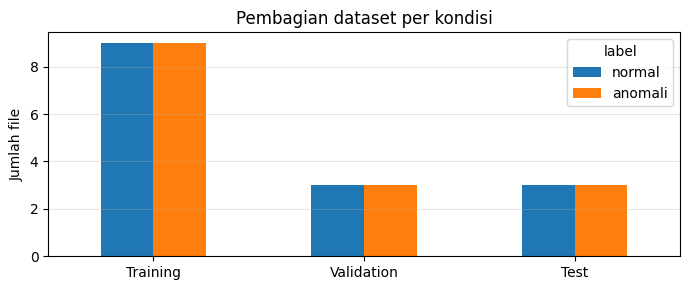

In [8]:
rng = np.random.default_rng(SEED)
file_train, file_valid, file_test = [], [], []
for kelas in KELAS:
    daftar = sorted(info.loc[info.label == kelas, "file"].tolist(), key=urut_angka)
    rng.shuffle(daftar)
    file_train += daftar[:9]
    file_valid += daftar[9:12]
    file_test += daftar[12:15]
assert set(file_train).isdisjoint(file_valid + file_test)
assert set(file_valid).isdisjoint(file_test)

train = fitur[fitur.file.isin(file_train)].copy()
valid = fitur[fitur.file.isin(file_valid)].copy()
test  = fitur[fitur.file.isin(file_test)].copy()

jumlah = pd.DataFrame({
    "Training":train.groupby("label").file.nunique(),
    "Validation":valid.groupby("label").file.nunique(),
    "Test":test.groupby("label").file.nunique()
}).reindex(KELAS)
print("Jumlah FILE, bukan window:")
display(jumlah)
jumlah.T.plot.bar(figsize=(7,3), rot=0)
plt.ylabel("Jumlah file"); plt.title("Pembagian dataset per kondisi")
plt.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

## Tahap 9 — Melihat sebaran fitur sebelum training

Kita hanya menggunakan **data training** untuk plot ini. Jika kedua kondisi terpisah dengan cukup jelas pada grafik, klasifikasi mungkin lebih mudah. Namun, dua fitur yang tumpang tindih tidak berarti model pasti gagal.

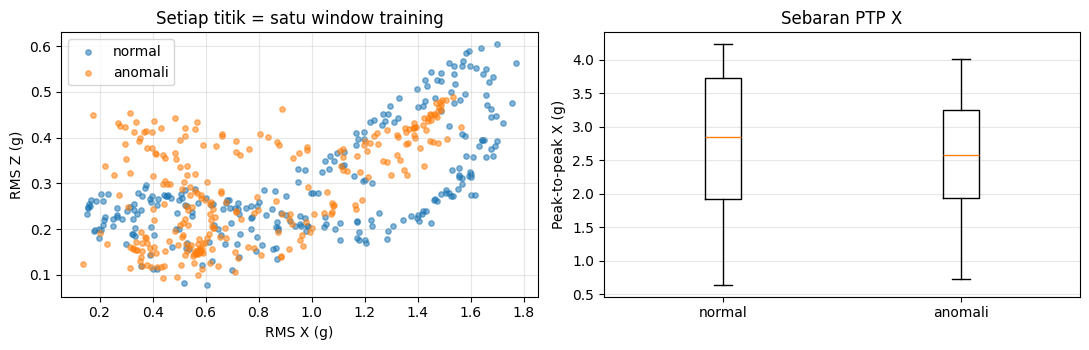

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11,3.6))
for kelas in KELAS:
    sub = train[train.label == kelas]
    axs[0].scatter(sub.rms_x, sub.rms_z, s=15, alpha=.55, label=kelas)
axs[0].set_xlabel("RMS X (g)"); axs[0].set_ylabel("RMS Z (g)")
axs[0].set_title("Setiap titik = satu window training")
axs[0].legend(); axs[0].grid(alpha=.3)
axs[1].boxplot([train.loc[train.label == k, "ptp_x"].to_numpy()
                for k in KELAS], tick_labels=KELAS)
axs[1].set_ylabel("Peak-to-peak X (g)"); axs[1].set_title("Sebaran PTP X")
axs[1].grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## Tahap 10 — Dua eksperimen: jumlah fitur dan jumlah pohon

Agar kesimpulannya jelas, kita ubah **satu hal pada satu waktu**:

1. **Model A:** 4 fitur, 15 pohon, kedalaman 4 (baseline).
2. **Model B:** 6 fitur, 15 pohon, kedalaman 4. Dibandingkan dengan A untuk memeriksa pengaruh **penambahan fitur**.
3. **Model C:** 6 fitur, 30 pohon, kedalaman 4. Dibandingkan dengan B untuk memeriksa pengaruh **jumlah pohon**.

Bandingkan menggunakan **validation**, bukan test. Model **C** disiapkan sebagai model TinyML yang akan diekspor, bukan karena nilainya selalu paling tinggi pada semua kelompok. Kita melaporkan hasil test model C sekali pada tahap berikutnya.

`StandardScaler` tidak dibutuhkan untuk Random Forest pada percobaan ini.


,model,accuracy,macro_f1
0,A: 4 fitur / 15 pohon,0.7056,0.7045
1,B: 6 fitur / 15 pohon,0.7111,0.7102
2,C: 6 fitur / 30 pohon,0.7278,0.7274


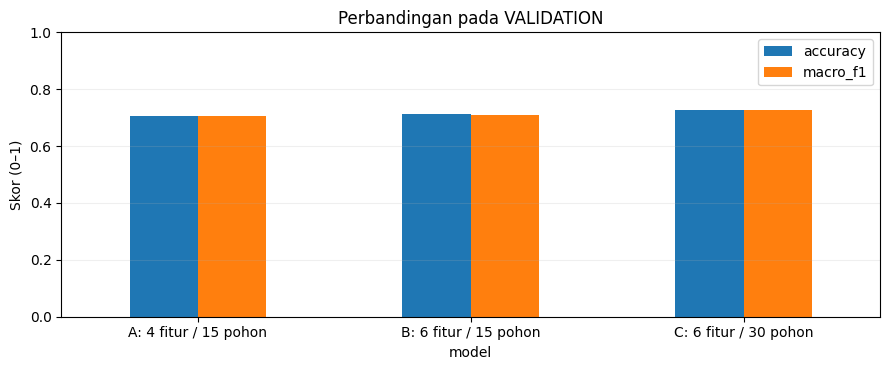

Model C: total node = 612
Model C: jumlah pohon = 30
Bandingkan A vs B untuk fitur, B vs C untuk jumlah pohon.


In [10]:
# Kode label: 0=NORMAL, 1=ANOMALI.
kode = {"normal": 0, "anomali": 1}
y_train, y_valid = train.label.map(kode), valid.label.map(kode)

# Model A: 4 fitur, 15 pohon.
model_A = RandomForestClassifier(
    n_estimators=15, max_depth=4, min_samples_leaf=3,
    random_state=SEED, n_jobs=-1)
model_A.fit(train[FITUR_4], y_train)
pA_valid = model_A.predict(valid[FITUR_4])

# Model B: 6 fitur, jumlah pohon tetap 15.
model_B = RandomForestClassifier(
    n_estimators=15, max_depth=4, min_samples_leaf=3,
    random_state=SEED, n_jobs=-1)
model_B.fit(train[FITUR], y_train)
pB_valid = model_B.predict(valid[FITUR])

# Model C: 6 fitur, jumlah pohon menjadi 30 (ini yang diekspor).
model = RandomForestClassifier(
    n_estimators=30, max_depth=4, min_samples_leaf=3,
    random_state=SEED, n_jobs=-1)
model.fit(train[FITUR], y_train)
p_valid = model.predict(valid[FITUR])

hasil_valid = pd.DataFrame([
    {"model": "A: 4 fitur / 15 pohon", "accuracy": accuracy_score(y_valid, pA_valid),
     "macro_f1": f1_score(y_valid, pA_valid, average="macro")},
    {"model": "B: 6 fitur / 15 pohon", "accuracy": accuracy_score(y_valid, pB_valid),
     "macro_f1": f1_score(y_valid, pB_valid, average="macro")},
    {"model": "C: 6 fitur / 30 pohon", "accuracy": accuracy_score(y_valid, p_valid),
     "macro_f1": f1_score(y_valid, p_valid, average="macro")},
])
display(hasil_valid.round(4))
hasil_valid.set_index("model")[["accuracy","macro_f1"]].plot.bar(
    figsize=(9,3.8), rot=0, ylim=(0,1))
plt.title("Perbandingan pada VALIDATION")
plt.ylabel("Skor (0–1)")
plt.grid(axis="y",alpha=.2)
plt.tight_layout(); plt.show()

print("Model C: total node =",sum(e.tree_.node_count for e in model.estimators_))
print("Model C: jumlah pohon =",len(model.estimators_))
print("Bandingkan A vs B untuk fitur, B vs C untuk jumlah pohon.")


## Tahap 11 — Evaluasi model pada data test

Setelah model 6 fitur ditetapkan, lakukan prediksi pada **file test yang berbeda**. Kita periksa accuracy, F1-score, confusion matrix, dan prediksi mayoritas per file.

**Ingat:** hasil test hanya menggambarkan rekaman pada percobaan ini. Jangan memilih hyperparameter berdasarkan test.

ACCURACY TEST (per window): 77.78%
              precision    recall  f1-score   support

      normal       0.84      0.69      0.76        90
     anomali       0.74      0.87      0.80        90

    accuracy                           0.78       180
   macro avg       0.79      0.78      0.78       180
weighted avg       0.79      0.78      0.78       180



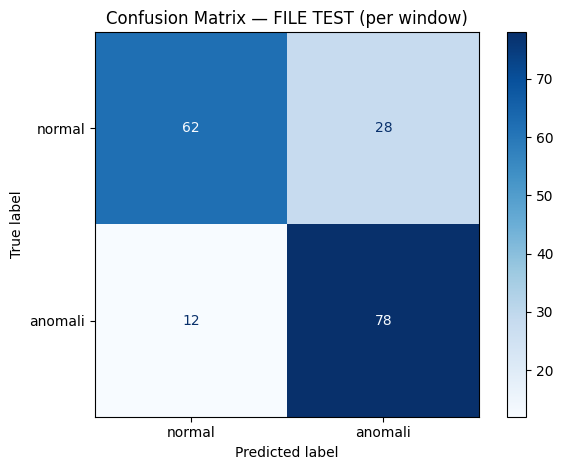

,file,label_asli,prediksi,jumlah_window
0,dataset_kompresor/anomali/anomali_10.csv,anomali,anomali,30
1,dataset_kompresor/anomali/anomali_12.csv,anomali,anomali,30
2,dataset_kompresor/anomali/anomali_15.csv,anomali,anomali,30
3,dataset_kompresor/normal/normal_02.csv,normal,anomali,30
4,dataset_kompresor/normal/normal_09.csv,normal,normal,30
5,dataset_kompresor/normal/normal_14.csv,normal,normal,30


Accuracy TEST per file: 83.33%


In [11]:
X_test, y_test = test[FITUR], test.label.map(kode)
p_test = model.predict(X_test)
test["prediksi"] = np.where(p_test == 1, "anomali", "normal")

print("ACCURACY TEST (per window):", f"{accuracy_score(y_test,p_test)*100:.2f}%")
print(classification_report(y_test,p_test,labels=[0,1],target_names=KELAS,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,p_test,labels=[0,1],
                                        display_labels=KELAS,cmap="Blues",values_format="d")
plt.title("Confusion Matrix — FILE TEST (per window)")
plt.tight_layout(); plt.show()

# Mayoritas hasil prediksi window dari file yang sama.
per_file = (test.groupby("file")
            .agg(label_asli=("label","first"),
                 prediksi=("prediksi",lambda s:s.mode().iloc[0]),
                 jumlah_window=("prediksi","size"))
            .reset_index())
display(per_file)
print("Accuracy TEST per file:",f"{accuracy_score(per_file.label_asli,per_file.prediksi)*100:.2f}%")

### Grafik tambahan — Feature importance

Menunjukkan fitur yang sering membantu Random Forest membagi data. Ini bukan bukti sebab-akibat secara fisik.

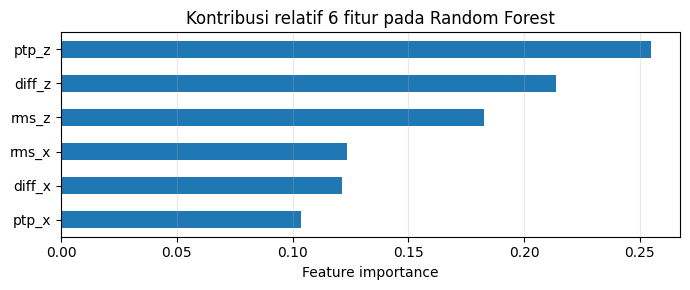

In [12]:
importance = pd.Series(model.feature_importances_, index=FITUR).sort_values()
importance.plot.barh(figsize=(7,3))
plt.title("Kontribusi relatif 6 fitur pada Random Forest")
plt.xlabel("Feature importance"); plt.grid(axis="x",alpha=.3)
plt.tight_layout(); plt.show()

## Tahap 12 — Memahami isi Random Forest melalui visualisasi Decision Tree

**Tujuan:** melihat dari mana asal angka dan aturan yang nanti disimpan dalam `model_rf.py`.

Random Forest kita berisi **30 Decision Tree**. Agar tidak terlalu rumit, kita visualisasikan **pohon pertama saja** (`model.estimators_[0]`). Pohon ini adalah bagian dari model yang **sudah dilatih**, bukan algoritma baru.

Pada setiap kotak dalam grafik:
- **Nama fitur dan batas (threshold)**, misalnya `ptp_z <= 1.27`: aturan untuk memilih cabang.
- **Gini**: ukuran campuran kedua kelas (semakin kecil, semakin homogen).
- **Samples**: banyak sampel training yang mencapai node (pohon memakai *bootstrap sampling*).
- **Value**: komposisi kelas pada node; **class**: kelas yang dominan.
- **Cabang kiri** dipilih jika kondisi `<=` benar; **cabang kanan** jika salah.

Angka threshold **dipelajari otomatis dari data training**. Saat diekspor ke `model_rf.py`, setiap node disimpan sebagai `(indeks_fitur, threshold, node_kiri, node_kanan, skor_anomali)`.

> **Catatan:** grafik hanya menampilkan pohon pertama sampai kedalaman 3 agar tetap terbaca. Random Forest memadukan prediksi semua pohon, bukan hanya pohon yang terlihat. Tidak ada data test yang dipakai untuk mempelajari pohon ini.


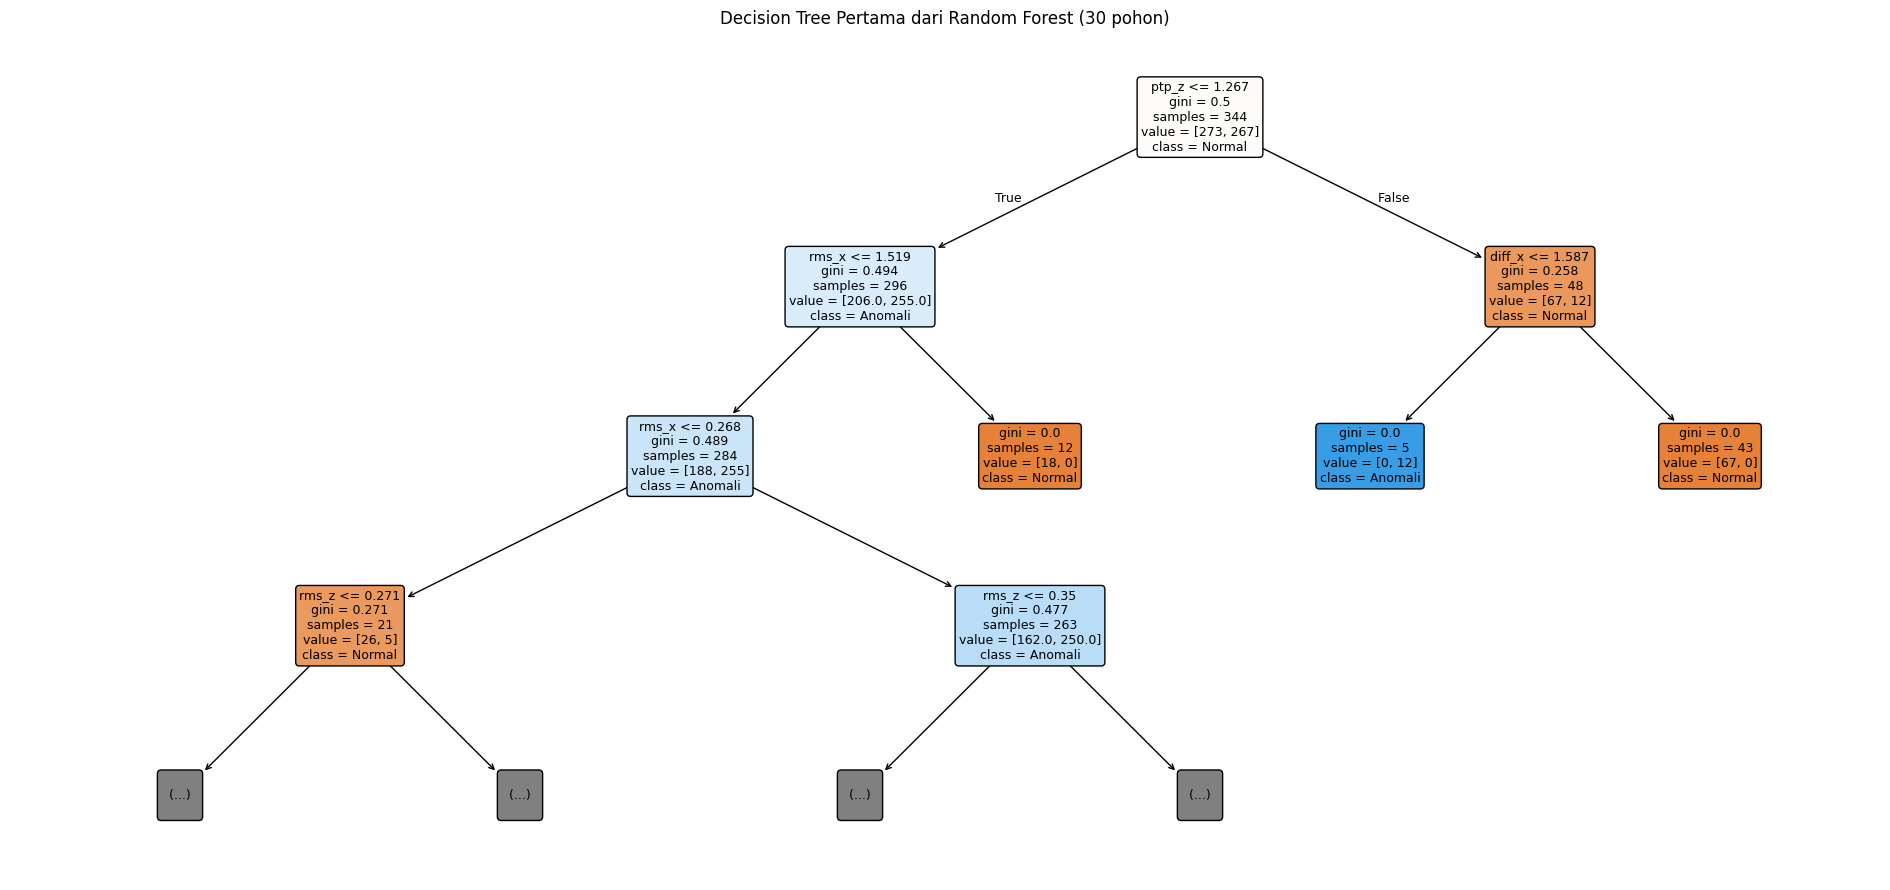

ATURAN PADA NODE PERTAMA (ROOT)
Indeks fitur : 3
Nama fitur   : ptp_z
Threshold    : 1.266846
Jika <=      : lanjut ke node 1
Jika >       : lanjut ke node 10

CONTOH SATU WINDOW VALIDATION:
 rms_x  rms_z  ptp_x  ptp_z  diff_x  diff_z
1.2714 0.1578 3.1873 0.7854  2.5207  0.2285
Node 0: ptp_z = 0.7854 <= 1.2668 → kiri
Node 1: rms_x = 1.2714 <= 1.5191 → kiri
Node 2: rms_x = 1.2714 > 0.2683 → kanan
Node 6: rms_z = 0.1578 <= 0.3500 → kiri
Node 7: LEAF (keputusan akhir pohon pertama)
Skor anomali dari pohon pertama: 0.5048
Skor anomali dari SELURUH Random Forest: 0.4516
Keduanya dapat berbeda karena Random Forest menggabungkan 30 pohon.


In [13]:
# Visualisasi satu Decision Tree (pohon pertama) dari Random Forest terlatih.
# Tidak mengubah atau melatih ulang model: hanya MEMBACA hasil training.
from sklearn.tree import plot_tree

pohon_pertama = model.estimators_[0]

plt.figure(figsize=(19, 9))
plot_tree(
    pohon_pertama,
    feature_names=FITUR,                 # Nama keenam fitur X dan Z
    class_names=["Normal", "Anomali"], # Label kelas 0 dan 1
    filled=True,                         # Warna menggambarkan kelas dominan
    rounded=True,
    max_depth=3,                         # Sederhanakan tampilan; model tetap utuh
    fontsize=9
)
plt.title("Decision Tree Pertama dari Random Forest (30 pohon)")
plt.tight_layout()
plt.show()

# Baca aturan pertama: nilai feature, threshold, serta tujuan cabang.
struktur = pohon_pertama.tree_
indeks_fitur = int(struktur.feature[0])
batas = float(struktur.threshold[0])
kiri = int(struktur.children_left[0])
kanan = int(struktur.children_right[0])

print("ATURAN PADA NODE PERTAMA (ROOT)")
print("Indeks fitur :", indeks_fitur)
print("Nama fitur   :", FITUR[indeks_fitur])
print("Threshold    :", round(batas, 6))
print("Jika <=      : lanjut ke node", kiri)
print("Jika >       : lanjut ke node", kanan)

# Contoh menggunakan SATU window dari data validation (bukan data test).
# Kita lihat keputusan yang dilalui contoh ini pada POHON PERTAMA saja.
contoh = valid[FITUR].iloc[[0]]
print("\nCONTOH SATU WINDOW VALIDATION:")
print(contoh.round(4).to_string(index=False))

jalur = pohon_pertama.decision_path(contoh.to_numpy())
node_terlewati = jalur.indices[jalur.indptr[0]:jalur.indptr[1]]
for node in node_terlewati:
    f_idx = int(struktur.feature[node])
    if f_idx == -2:  # Pada sklearn, -2 menandai leaf.
        print(f"Node {node}: LEAF (keputusan akhir pohon pertama)")
    else:
        nilai = float(contoh.iloc[0, f_idx])
        ambang = float(struktur.threshold[node])
        cabang = "kiri" if nilai <= ambang else "kanan"
        print(f"Node {node}: {FITUR[f_idx]} = {nilai:.4f} "
              f"{'<=' if nilai <= ambang else '>'} {ambang:.4f} → {cabang}")

print("Skor anomali dari pohon pertama:",
      round(float(pohon_pertama.predict_proba(contoh.to_numpy())[0, 1]), 4))
print("Skor anomali dari SELURUH Random Forest:",
      round(float(model.predict_proba(contoh)[0, 1]), 4))
print("Keduanya dapat berbeda karena Random Forest menggabungkan 30 pohon.")


**Pertanyaan untuk mahasiswa:** (1) Fitur apa yang digunakan pada node pertama? (2) Berapa threshold-nya? (3) Mengapa prediksi satu pohon bisa berbeda dari gabungan Random Forest? Bandingkan angka yang ditampilkan di atas dengan baris awal `TREES` pada `model_rf.py` setelah ekspor.

## Tahap 13 — Ekspor model menjadi `model_rf.py` untuk MicroPython

ESP32 tidak dapat langsung menjalankan file `joblib` atau library sklearn. Kita ubah setiap pohon menjadi daftar node sederhana berisi kondisi perbandingan fitur.

`model_rf.py` dapat dijalankan dengan **MicroPython biasa tanpa library ML tambahan**. Ukurannya dicetak agar mahasiswa dapat mengamati keterbatasan embedded.

In [14]:
def ekspor_rf(rf):
    """Mengubah Random Forest sklearn -> kode Python berisi decision-tree kecil."""
    assert list(rf.classes_) == [0, 1], "Kelas model harus [0,1]."
    lines = [
        '# Model Random Forest untuk MicroPython (dibuat di Google Colab)',
        '# Kelas: 0=NORMAL, 1=ANOMALI',
        '# Urutan input: ' + ', '.join(FITUR),
        'TREES = ('
    ]
    for est in rf.estimators_:
        tr = est.tree_
        lines.append('    (')
        for i in range(tr.node_count):
            left = int(tr.children_left[i])
            right = int(tr.children_right[i])
            leaf = left == -1
            feat_idx = -1 if leaf else int(tr.feature[i])
            threshold = 0.0 if leaf else float(tr.threshold[i])
            counts = tr.value[i][0]
            p_anomali = float(counts[1] / np.sum(counts))
            lines.append('        (%d, %.17g, %d, %d, %.17g),' %
                         (feat_idx, threshold, left, right, p_anomali))
        lines.append('    ),')
    lines += [
        ')',
        '',
        'def predict_proba(features):',
        '    """Kembalikan skor/probabilitas kelas ANOMALI."""',
        '    total = 0.0',
        '    for nodes in TREES:',
        '        i = 0',
        '        while True:',
        '            f, batas, left, right, p1 = nodes[i]',
        '            if f == -1:',
        '                total += p1',
        '                break',
        '            i = left if features[f] <= batas else right',
        '    return total / len(TREES)',
        '',
        'def predict(features):',
        '    return 1 if predict_proba(features) > 0.5 else 0',
        ''
    ]
    return '\n'.join(lines)

hasil = Path('hasil_tinyml_xz_6fitur')
hasil.mkdir(exist_ok=True)
file_model = hasil/'model_rf.py'
file_model.write_text(ekspor_rf(model),encoding='utf-8')
print('File dibuat:',file_model)
print('Ukuran:',round(file_model.stat().st_size/1024,1),'KB')

File dibuat: hasil_tinyml_xz_6fitur/model_rf.py
Ukuran: 30.0 KB


## Tahap 14 — Verifikasi ekspor dan kesesuaian rumus fitur

Sebelum mengunggah kode ke ESP32, kita memastikan dua hal:

1. `model_rf.py` memberikan **prediksi yang sama** dengan sklearn pada seluruh window test.
2. Perhitungan 6 fitur menggunakan **operasi sederhana seperti MicroPython** sesuai dengan perhitungan NumPy di Colab.

Ini belum membuktikan program berjalan di hardware ESP32, tetapi mendeteksi banyak kesalahan konversi sebelum deployment.

In [15]:
# Import model hasil ekspor sebagai modul Python biasa.
spec=importlib.util.spec_from_file_location('model_rf_xz',str(file_model.resolve()))
modul=importlib.util.module_from_spec(spec)
spec.loader.exec_module(modul)

X=X_test.to_numpy(dtype=float)
prob_sklearn=model.predict_proba(X_test)[:,1]  # Nama fitur tetap konsisten, tanpa warning sklearn
prob_export=np.array([modul.predict_proba(x) for x in X])
pred_export=np.array([modul.predict(x) for x in X])
print('Selisih probabilitas terbesar:',np.max(np.abs(prob_sklearn-prob_export)))
print('Kecocokan prediksi:',np.mean(pred_export == p_test)*100,'%')
assert np.all(pred_export == p_test), 'Prediksi model ekspor tidak sesuai sklearn!'
assert np.max(np.abs(prob_sklearn-prob_export)) < 1e-8

# Rumus fitur sederhana yang nantinya digunakan di ESP32 (tanpa NumPy).
def fitur_esp_seperti_python(raw_xz):
    """Implementasi sederhana 6 fitur yang sama dengan kode MicroPython."""
    pasangan = []
    for col in (0,1):
        nilai = [int(v) for v in raw_xz[:,col]]
        rata = sum(nilai) / len(nilai)
        rms = math.sqrt(sum((v - rata) ** 2 for v in nilai) / len(nilai)) / SKALA
        ptp = (max(nilai) - min(nilai)) / SKALA
        diff = sum(abs(nilai[i] - nilai[i-1]) for i in range(1, len(nilai))) / (len(nilai)-1) / SKALA
        pasangan.append((rms,ptp,diff))
    return [pasangan[0][0],pasangan[1][0],
            pasangan[0][1],pasangan[1][1],
            pasangan[0][2],pasangan[1][2]]

# Periksa seluruh window test, bukan hanya satu contoh.
selisih_fitur=[]
selisih_prediksi=0
for _, r in test.iterrows():
    raw=rekaman[r['file']]['xz'][(int(r['window'])-1)*WINDOW:int(r['window'])*WINDOW]
    fitur_numpy=np.array([r[n] for n in FITUR])
    fitur_mcu=np.array(fitur_esp_seperti_python(raw))
    selisih_fitur.append(np.max(np.abs(fitur_numpy-fitur_mcu)))
    if modul.predict(fitur_numpy)!=modul.predict(fitur_mcu):
        selisih_prediksi += 1
print('Selisih fitur terbesar (Colab vs rumus sederhana):',max(selisih_fitur))
print('Perbedaan prediksi setelah hitung fitur:',selisih_prediksi)
assert max(selisih_fitur)<1e-5
assert selisih_prediksi==0
print('LOLOS: model ekspor dan rumus fitur konsisten.')

Selisih probabilitas terbesar: 2.220446049250313e-16
Kecocokan prediksi: 100.0 %
Selisih fitur terbesar (Colab vs rumus sederhana): 2.220446049250313e-16
Perbedaan prediksi setelah hitung fitur: 0
LOLOS: model ekspor dan rumus fitur konsisten.


## Tahap 15 — Membuat `main.py` untuk ESP32

Program MicroPython berikut akan:

1. Menghubungkan ESP32 dengan MPU6050 (SDA=GPIO21, SCL=GPIO22).
2. Mengambil **200 sampel X dan Z** dengan target 200 Hz.
3. Menghitung 6 fitur dengan rumus **yang sama** dengan Colab.
4. Menjalankan prediksi `NORMAL` / `ANOMALI` **secara lokal di ESP32**.
5. Melaporkan waktu inferensi, sampling aktual, dan RAM tersisa.

MPU6050 tetap dibaca melalui 6 byte X/Y/Z sekaligus, tetapi **nilai Y sengaja tidak dipakai**. Config MPU6050 tetap **±4g dan filter lama (`0x02`)** agar cocok dengan model yang dilatih dari dataset lama. Mengubah range/filter saat inferensi dapat menggeser pola sinyal, jadi eksperimen dengan konfigurasi baru harus direkam dan dilatih kembali.

In [16]:
# Kode yang akan ditulis menjadi file main.py (berjalan pada ESP32).
MAIN_CODE = r'''# main.py -- TinyML getaran kompresor, sumbu X dan Z, 6 fitur
# Upload bersama model_rf.py ke ESP32 MicroPython.
from machine import Pin, I2C
from array import array
import time, math, gc
import model_rf

FS = 200
WINDOW = 200
SKALA = 8192.0     # Cocok dengan dataset lama MPU6050 +/-4g
PERIODE_US = 1000000 // FS

i2c = I2C(0, sda=Pin(21), scl=Pin(22), freq=400000)
daftar = i2c.scan()
if 0x68 in daftar:
    MPU = 0x68
elif 0x69 in daftar:
    MPU = 0x69
else:
    raise OSError("MPU6050 tidak ditemukan (periksa kabel dan 3.3V)")

# Konfigurasi disamakan dengan perekaman awal
# PWR_MGMT_1: bangunkan sensor
i2c.writeto_mem(MPU, 0x6B, b'\x01')
# DLPF_CFG = 2, bandwidth accel ~94 Hz (sesuai data lama)
i2c.writeto_mem(MPU, 0x1A, b'\x02')
# Register sample-rate divider sengaja tidak diubah (mengikuti logger lama)
# ACCEL_CONFIG = +/-4g
i2c.writeto_mem(MPU, 0x1C, b'\x08')
time.sleep_ms(100)

def signed16(hi,lo):
    n = (hi << 8) | lo
    return n - 65536 if n >= 32768 else n

def baca_window():
    xs, zs = array('h'), array('h')
    target = time.ticks_us()
    waktu_awal = None
    waktu_akhir = None
    terlambat = 0
    clip_x = 0
    clip_z = 0
    for i in range(WINDOW):
        sekarang = time.ticks_us()
        selisih = time.ticks_diff(target, sekarang)
        if selisih > 0:
            time.sleep_us(selisih)
        elif selisih < -PERIODE_US:
            terlambat += 1
            target = sekarang
        cap = time.ticks_us()
        if waktu_awal is None:
            waktu_awal = cap
        waktu_akhir = cap
        data = i2c.readfrom_mem(MPU, 0x3B, 6)
        x = signed16(data[0],data[1])
        z = signed16(data[4],data[5])
        xs.append(x)
        zs.append(z)
        if x <= -32768 or x >= 32767: clip_x += 1
        if z <= -32768 or z >= 32767: clip_z += 1
        target = time.ticks_add(target, PERIODE_US)
    durasi = time.ticks_diff(waktu_akhir,waktu_awal)
    fs_aktual = (WINDOW-1)*1000000.0/durasi if durasi > 0 else 0
    return xs, zs, fs_aktual, terlambat, clip_x, clip_z

def fitur_sumbu(angka):
    n = len(angka)
    rata = sum(angka) / n
    total_kuadrat = 0.0
    total_perubahan = 0.0
    minimum, maksimum = 32767, -32768
    sebelumnya = None
    for x in angka:
        d = x - rata
        total_kuadrat += d*d
        if x < minimum: minimum = x
        if x > maksimum: maksimum = x
        if sebelumnya is not None:
            total_perubahan += abs(x-sebelumnya)
        sebelumnya = x
    rms = math.sqrt(total_kuadrat/n) / SKALA
    ptp = (maksimum-minimum) / SKALA
    diff = total_perubahan/(n-1) / SKALA
    return rms, ptp, diff

def ekstrak_fitur(xs,zs):
    rx, px, dx = fitur_sumbu(xs)
    rz, pz, dz = fitur_sumbu(zs)
    # Input model: rms_x,rms_z,ptp_x,ptp_z,diff_x,diff_z
    return (rx, rz, px, pz, dx, dz)

print('TinyML siap. Sumbu XZ, 6 fitur, 30 pohon RF')
print('Baca MPU6050 -> fitur -> prediksi tanpa laptop untuk komputasi.')
nomor = 0
while True:
    x,z,fs_aktual,telat,clip_x,clip_z = baca_window()
    angka = ekstrak_fitur(x,z)
    mulai = time.ticks_us()
    skor = model_rf.predict_proba(angka)
    waktu_ms = time.ticks_diff(time.ticks_us(),mulai)/1000.0
    hasil = 'ANOMALI' if skor > 0.5 else 'NORMAL'
    nomor += 1
    print('Window', nomor, '->', hasil,
          '| skor:', round(skor,3),
          '| fs:', round(fs_aktual,1), 'Hz',
          '| inferensi:', round(waktu_ms,2), 'ms')
    if telat or abs(fs_aktual-FS) > FS*0.05:
        print('  PERINGATAN: sampling tidak stabil')
    if clip_x or clip_z:
        print('  PERINGATAN: clipping X/Z:',clip_x,clip_z)
    gc.collect()
    print('  RAM bebas:',gc.mem_free(),'byte')
'''
file_utama=hasil/'main.py'
file_utama.write_text(MAIN_CODE, encoding='utf-8')
print('Dibuat:',file_utama, '| ukuran:',round(file_utama.stat().st_size/1024,1),'KB')

Dibuat: hasil_tinyml_xz_6fitur/main.py | ukuran: 3.6 KB


## Tahap 16 — Unduh berkas hasil untuk ESP32

File output:

| Nama file | Tujuan |
|---|---|
| **`model_rf.py`** | Model Random Forest kecil untuk MicroPython |
| **`main.py`** | Baca MPU6050 → 6 fitur → prediksi lokal |
| `random_forest_colab.joblib` | Model asli untuk komputer (bukan untuk ESP32) |
| `dataset_fitur.csv` | Semua window beserta 6 fitur |
| `prediksi_window_test.csv` | Prediksi setiap window test |
| `prediksi_file_test.csv` | Voting prediksi per file |
| `rekap_kualitas_data.csv` | Ringkasan clipping dan sampling |
| `README.txt` | Petunjuk upload serta batasan eksperimen |

**Upload ke ESP32 hanya `model_rf.py` dan `main.py`.**

In [17]:
# Menyimpan semua hasil dan ZIP untuk diunduh dari Colab.
fitur.to_csv(hasil/'dataset_fitur.csv',index=False)
test.to_csv(hasil/'prediksi_window_test.csv',index=False)
per_file.to_csv(hasil/'prediksi_file_test.csv',index=False)
info.drop(columns=['hash_xz']).to_csv(hasil/'rekap_kualitas_data.csv',index=False)
joblib.dump({'model':model,'features':FITUR,'FS':FS,'WINDOW':WINDOW,'SKALA':SKALA},
            hasil/'random_forest_colab.joblib')

README = '''PRAKTIKUM TinyML KOMPRESOR - ESP32 + MPU6050 (6 FITUR XZ)

A. GOOGLE COLAB
1. Jalankan semua cell notebook berurutan.
2. Upload satu ZIP dataset kelompok dengan 15 normal dan 15 anomali.
3. Amati grafik clipping, train/validation/test, dan confusion matrix.
4. Unduh ZIP yang dihasilkan.

B. ESP32 (MicroPython)
1. Pastikan pin MPU6050: VCC 3V3, GND GND, SDA GPIO21, SCL GPIO22.
2. Salin model_rf.py dan main.py ke ROOT penyimpanan ESP32 melalui Thonny.
3. Reset ESP32 dan lihat output Serial/Thonny Shell.
4. Prediksi dikerjakan di ESP32; komputer hanya untuk catu daya/monitor opsional.
5. Catat output NORMAL/ANOMALI, fs aktual, inferensi, dan RAM bebas.

CATATAN PENTING
- Model memakai sumbu X dan Z saja, 6 fitur: rms_x,rms_z,ptp_x,ptp_z,diff_x,diff_z.
- Dataset lama memakai MPU6050 +/-4g, faktor 8192 LSB/g.
- Jangan mengubah range, filter, window, atau orientasi pemasangan antara
  training dan pengukuran. Bila diubah, ambil data baru dan latih ulang.
- Ini pengenalan pola GETARAN, bukan diagnosis kerusakan kompresor.
- Tidak aman mengubah satu tumpuan saja sampai kompresor miring/tidak stabil.
- Kode ekspor diuji di Colab, tetapi kinerja MicroPython harus diuji pada
  board ESP32 dan versi firmware yang digunakan.
- Sampling 200 Hz merupakan target; cek fs aktual dan clipping.
- Jangan gunakan Thonny dan aplikasi serial lain bersamaan pada port yang sama.
'''
(hasil/'README.txt').write_text(README,encoding='utf-8')

# Jangan ikutkan cache Python dari proses verifikasi pada ZIP yang diunduh.
shutil.rmtree(hasil/'__pycache__', ignore_errors=True)
nama_hasil = shutil.make_archive('hasil_tinyml_xz_6fitur_kompresor','zip',root_dir=hasil)
print('File ZIP hasil:',nama_hasil)
files.download(nama_hasil)

File ZIP hasil: /content/hasil_tinyml_xz_6fitur_kompresor.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Tahap 17 — Pengujian TinyML di perangkat (tanpa training ulang)

1. Sambungkan ESP32 ke Thonny, salin **`model_rf.py` dan `main.py`** ke penyimpanan internal ESP32.
2. Reset ESP32. Pastikan pesan awal dan prediksi muncul pada Shell/Serial Monitor.
3. Bandingkan hasil selama **kondisi normal** dan **kondisi percobaan kedua** yang aman, tanpa mengubah posisi sensor.
4. Catat nilai **frekuensi sampling aktual**, **waktu inferensi**, dan **RAM bebas**.
5. Ingat bahwa prediksi awal bisa salah pada kondisi baru; nilai `skor` bukan jaminan probabilitas kerusakan mesin.

### Pertanyaan praktikum

1. Mengapa train/test dibagi berdasarkan **file**, bukan menurut window yang diacak?
2. Apakah jumlah fitur lebih banyak selalu meningkatkan akurasi? Jelaskan menggunakan hasil **validation**.
4. Bandingkan waktu inferensi pada ESP32 dengan durasi pengambilan satu window.

**Kesimpulan:** pelatihan dilakukan di Colab, sementara akuisisi, ekstraksi fitur, dan prediksi terjadi secara mandiri pada ESP32.


**Ingat:** Evaluasi pada ESP32 dengan data baru perlu dilakukan karena pengaturan sensor, mounting, dan kondisi operasi dapat mengubah distribusi data.
